# The IRRBB validation tests: golden shocks, sum of parts, parameter stability and the change at a limit breach

**Question:** which of the seven IRRBB validation tests of the engine flag the weaknesses of the bank that failed in 2023 at its three valuation dates, and does each test turn from green to red when its input is deliberately broken, so that a green means something?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- name the seven IRRBB validation tests of the engine, what each one tests, and the rule that gives its light;
- run each test on the inputs the committed documents hold and read its statistic and its light at the three dates;
- show that a test is not vacuous by changing one input and watching its light change;
- read the stability of the replicating-portfolio weights across estimation windows and explain why it is the weakest result of the case;
- say what the tests state and what they do not: they are internal gates of Contraste, not regulatory thresholds.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14 (the interest rate risk in the banking book of the bank that failed in March 2023) at three valuation dates, 2021-Q4, 2022-Q2 and 2022-Q4, and case C15 (the synthetic Banco Andino on a CLP and UF balance sheet) for the Chilean test. C14 uses the FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates); C15 uses the CMF aggregates of August 2026 and the curves of the Banco Central de Chile (series F022); all four are public sources of the licence class `mirror-allowed`. C14 is real in aggregate and synthetic in behaviour; C15 is a synthetic bank on real curves.

- **Files read:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`, `out_of_sample`) and `models-svb-2021-2022.json` (`fit.nmd_models`, the replicating weights by window), and `data/derived/C15/short-uf.json` (`outputs.legs`, `curves`, `eve`).

The next cell loads the files.

In [2]:
# Load the three valuation dates of C14, the model document and the C15 variant (three folders below the root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((derived / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
c15 = json.loads((derived / "C15" / "short-uf.json").read_text(encoding="utf-8"))
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
battery = {}
print("valuation dates of C14:", [d["outputs"]["valuation_date"] for d in docs.values()])
print("C15:", c15["outputs"]["as_of"])

valuation dates of C14: ['2021-12-31', '2022-06-30', '2022-12-31']
C15: 2026-09-03


## Method

The engine holds seven IRRBB validation tests in `riskvalidation.validation.irrbb`. Each is a plain function that returns one `TestResult` and states its light rule in its docstring. They follow the lessons that the research turned into tests (dossier 05, D.7): an implementation must reproduce the standard's own examples, its parts must add up to the whole, a behavioural parameter must be stable, the behavioural layer must be reported beside the contractual reading, a change in a behavioural assumption must not coincide with a breach, and a projection must be compared with what happened.

| Test | What it tests | Rule of the light |
|---|---|---|
| `irrbb.srp31_92_goldens` | the worked example of the standard | green if every value is within its tolerance |
| `irrbb.cmf_annex1_goldens` | the Chilean Annex 1 formulas and table | green if all 19 cases are exact |
| `irrbb.eve_sum_of_parts` | EVE of the whole equals the sum of its items | green if the relative residual is at most `rel_tol` |
| `irrbb.nmd_parameter_stability` | replicating weights across windows | green, amber, red by the sup-norm distance |
| `irrbb.eve_with_without_behavioural` | the two readings together | green, amber, red; red if a breach is hidden |
| `irrbb.behavioural_change_at_breach` | a change that coincides with a breach | red if any |
| `irrbb.nii_out_of_sample` | projection against the realised change | green, amber, red by the relative error |

The gates are **Contraste internal gates**, stated as such in each docstring and recorded in the result's `policy_version` and `extras["thresholds"]`; none states a compliance claim. A test that cannot be evaluated returns the light `not_evaluated` with the reason in `notes`, never a made-up number.

### Step 1: the two golden tests

A golden test recomputes a value the primary source prints and compares it with the print. `irrbb.srp31_92_goldens` was read in notebook 02 (the four values of the worked example at 3.5 years). `irrbb.cmf_annex1_goldens` checks 19 cases of the Chilean Annex 1: the offset table `cmf_pair` on both signs (8 cases), the table of shock sizes (5 rows), the indexation charge, the `annex1_delta_eve` example (3 cases) and the worked example of Annex 1 (2 cases). Its statistic is the number of failed cases, and an exception counts as a failed case. The next cell runs both and then tightens the tolerance of the first to show how its light changes.

In [3]:
# Run the two golden tests, then tighten the tolerance of the first one
runs = [rv_irrbb.srp31_92_goldens(), rv_irrbb.cmf_annex1_goldens()]
tight = rv_irrbb.srp31_92_goldens(tolerance_bp=0.01)
for run in runs + [tight]:
    print(f"{run.test_id}: {LIGHT[run.light.value]} | statistic {run.statistic:.4f} | n = {run.n}")
print("failed cases of the Chilean test:", runs[1].extras.get("failed"))
print("tolerances of the tightened run:", tight.extras["thresholds"])
battery["irrbb.srp31_92_goldens"] = [runs[0].light.value] * 3
battery["irrbb.cmf_annex1_goldens"] = [runs[1].light.value] * 3

irrbb.srp31_92_goldens: green | statistic 0.0393 | n = 4
irrbb.cmf_annex1_goldens: green | statistic 0.0000 | n = 19
irrbb.srp31_92_goldens: red | statistic 0.0393 | n = 4
failed cases of the Chilean test: []
tolerances of the tightened run: {'tolerance_scalar': 0.0005, 'tolerance_bp': 0.01}


The two golden tests run on the engine alone: the statistic of the first is 0.0393 over four values, the flattener's deviation from the printed -1.6, and the second passes 19 of 19 cases of the Chilean Annex 1 with an empty list of failures. The third line is the control: the same test with a tolerance of 0.01 bp instead of 0.05 turns the same statistic into a failure, because the printed value has one decimal and the engine does not. What follows is that a golden test is a statement about the precision of the source and not about correctness in general: it says the implementation reproduces what the sources print, and nothing about a balance sheet.

### Step 2: the sum of parts

The EVE is linear in the cash flows, $EVE(x) = \sum_k x_k\, DF_k$, so the EVE of the whole balance sheet must equal the sum of the EVEs of its items. The test `irrbb.eve_sum_of_parts` computes the EVE of each item row and adds them, sets the sum against the EVE of the aggregated flows, and takes the relative residual $|\sum_i EVE_i - EVE_{whole}| / |EVE_{whole}|$; it is green at most `rel_tol = 1e-9`. The 17 item vectors are in the balance sheet of each date, and the whole is the base EVE of the first scenario. The next cell runs it at the three dates.

In [4]:
# Run the sum-of-parts test at the three dates with the 17 item vectors
inputs = {}
battery["irrbb.eve_sum_of_parts"] = []
for q, d in docs.items():
    o = d["outputs"]
    r0 = np.array(o["curve"]["zero_rates_at_midpoints"])
    item_flows = np.zeros((len(o["balance_sheet"]["items"]), 19))
    for i, item in enumerate(o["balance_sheet"]["items"]):
        for flow in item["cash_flows"]["behavioural"]:
            item_flows[i, flow["bucket"] - 1] += flow["amount"]
    inputs[q] = (item_flows, r0, o["scenarios"][0]["base_eve"])
    run = rv_irrbb.eve_sum_of_parts(*inputs[q][:2], MID, inputs[q][2])
    battery["irrbb.eve_sum_of_parts"].append(run.light.value)
    print(f"{q}: items {run.n} | sum of the parts {run.extras['sum_of_parts']:,.3f}")
    print(f"    whole {run.extras['whole_eve']:,.3f} | relative residual {run.metric:.2e} | {LIGHT[run.light.value]}")

2021-Q4: items 17 | sum of the parts 8,982,670.014
    whole 8,982,670.014 | relative residual 2.07e-16 | green
2022-Q2: items 17 | sum of the parts 7,036,780.156
    whole 7,036,780.156 | relative residual 1.06e-15 | green
2022-Q4: items 17 | sum of the parts 5,257,967.562
    whole 5,257,967.562 | relative residual 2.48e-15 | green


At each date the 17 items add up to the whole to within floating-point noise, a relative residual between 10^-16 and 10^-15, six orders of magnitude under the gate. That is the expected result of a linear measure and it says the aggregation of the balance sheet did not lose or double an item. A test that can only pass is worth nothing, though, so the next step feeds it broken inputs and the same engine is then run on a second, synthetic bank, the Chilean peso leg of C15.

In [5]:
# The same test on the CLP leg of the synthetic bank of C15
leg = next(l for l in c15["outputs"]["legs"] if l["leg"] == "CLP")
flows_c15 = np.zeros((len(leg["items"]), 19))
for i, item in enumerate(leg["items"]):
    for flow in item["cash_flows"]:
        flows_c15[i, flow["bucket"] - 1] += flow["amount"]
r_c15 = np.array(c15["outputs"]["curves"]["clp"]["zero_rates_at_midpoints"])
run15 = rv_irrbb.eve_sum_of_parts(flows_c15, r_c15, MID, c15["outputs"]["eve"]["base_eve_clp"])
print(f"C15, CLP leg: items {run15.n} | relative residual {run15.metric:.2e} | {LIGHT[run15.light.value]}")

C15, CLP leg: items 12 | relative residual 2.35e-16 | green


A test that always passes is worth nothing, so the next cell changes one input and watches the light. First, the whole EVE is shifted by one unit (one thousand dollars, a relative change of about $10^{-7}$): the gate of $10^{-9}$ turns it red. Second, the same shift under a looser gate, `rel_tol = 1e-6`, stays green. Third, one item is left out of the item rows while the whole keeps it, which is the error the test exists to catch.

2022-Q2, as it is            relative residual 1.06e-15 | green
whole + 1, gate 1e-9         relative residual 1.42e-07 | red
whole + 1, gate 1e-6         relative residual 1.42e-07 | green
one item left out            relative residual 2.03e+00 | red


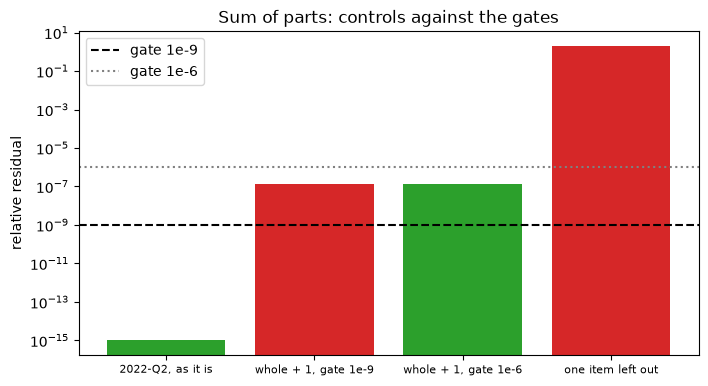

In [6]:
# Negative controls on 2022-Q2: shift the whole by one unit, loosen the gate, and leave one item out
item_flows, r0, whole = inputs["2022-Q2"]
cases = {
    "2022-Q2, as it is": rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole),
    "whole + 1, gate 1e-9": rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0),
    "whole + 1, gate 1e-6": rv_irrbb.eve_sum_of_parts(item_flows, r0, MID, whole + 1.0, rel_tol=1e-6),
    "one item left out": rv_irrbb.eve_sum_of_parts(item_flows[1:], r0, MID, whole),
}
for label, run in cases.items():
    print(f"{label:28s} relative residual {run.metric:.2e} | {LIGHT[run.light.value]}")
colours = {"green": "tab:green", "red": "tab:red"}
fig, ax = plt.subplots(figsize=(8, 4.2))
heights = [max(run.metric, 1e-18) for run in cases.values()]
ax.bar(list(cases), heights, color=[colours[run.light.value] for run in cases.values()])
ax.axhline(1e-9, color="black", linestyle="--", label="gate 1e-9")
ax.axhline(1e-6, color="grey", linestyle=":", label="gate 1e-6")
ax.set_yscale("log")
ax.set_ylabel("relative residual")
ax.set_title("Sum of parts: controls against the gates")
ax.tick_params(axis="x", labelsize=8)
ax.legend()
plt.show()

The bars are coloured by the light the test returned. The untouched balance sheet sits at the floor of the chart, so its bar is almost invisible; shifting the whole by one unit lifts the residual to 1.4 x 10^-7, above the dashed gate of 10^-9, and the light turns red; the same shift under the dotted gate of 10^-6 stays green, so the gate decides what the test can see; and dropping one item moves the residual to 2.03 and the light to red. The test cannot see an error that is present in both the items and the whole, because it compares one with the other. The figure shows that the test is alive, not that the balance sheet is right.

### Step 3: the stability of the replicating weights

Notebook 03 showed that the replicating-portfolio weights are an estimate with a flat objective. `irrbb.nmd_parameter_stability` measures how much they move when the estimation window moves (dossier 05, D.3; BCBS d368). The pipeline re-estimates the weights on three windows of 16 quarters ending at the valuation date, one year before and two years before. The statistic is the largest sup-norm distance between the weights of consecutive windows, $\max_j |w_{a,j} - w_{b,j}|$; the metric is the largest change of the weighted average maturity between consecutive windows, in years. The light is green at most 0.10, amber at most 0.25, red above. The next cell runs it from the committed weights of each date and prints the weights, the maturities and the distances.

2021-Q4: windows ending ['2019-12-31', '2020-12-31', '2021-12-31']
    weight on the 10-year tranche by window [0.794, 0.426, 0.951]
    average maturity (y) by window [3.995, 2.204, 4.759]
    distances [0.367, 0.524] | statistic 0.5243
    maturity change (y) 2.5559 | red
2022-Q2: windows ending ['2020-06-30', '2021-06-30', '2022-06-30']
    weight on the 10-year tranche by window [0.544, 0.74, 0.837]
    average maturity (y) by window [2.775, 3.734, 4.205]
    distances [0.197, 0.097] | statistic 0.1967
    maturity change (y) 0.9588 | amber
2022-Q4: windows ending ['2020-12-31', '2021-12-31', '2022-12-31']
    weight on the 10-year tranche by window [0.426, 0.951, 1.0]
    average maturity (y) by window [2.204, 4.759, 5.0]
    distances [0.524, 0.049] | statistic 0.5243
    maturity change (y) 2.5559 | red


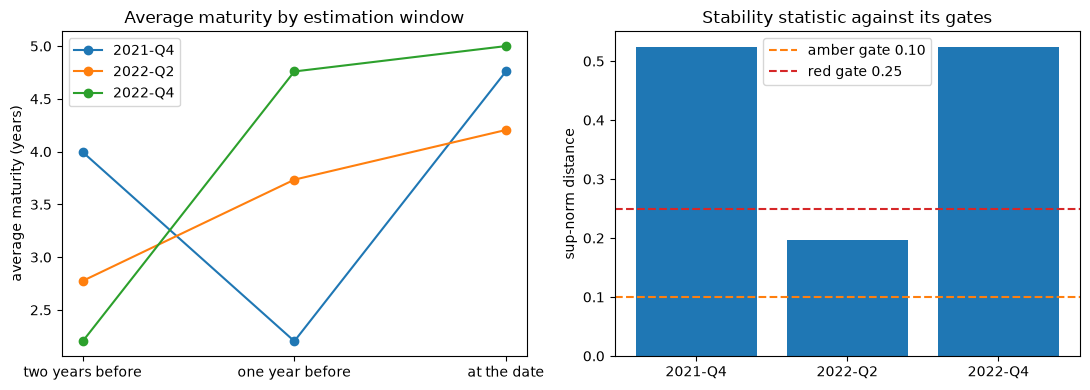

In [7]:
# Run the stability test on the three estimation windows of each date
windows = {}
battery["irrbb.nmd_parameter_stability"] = []
for q, d in docs.items():
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == d["outputs"]["valuation_date"])
    weights = np.array([w["weights"] for w in model["stability"]])
    maturities = np.array([t["maturity_years"] for t in model["tranches"]])
    run = rv_irrbb.nmd_parameter_stability(weights, maturities)
    windows[q] = run
    battery["irrbb.nmd_parameter_stability"].append(run.light.value)
    print(f"{q}: windows ending {[w['window_end'] for w in model['stability']]}")
    print(f"    weight on the 10-year tranche by window {[round(float(w[-1]), 3) for w in weights]}")
    print(f"    average maturity (y) by window {[round(x, 3) for x in run.extras['weighted_average_maturity']]}")
    print(f"    distances {[round(x, 3) for x in run.extras['distances']]} | statistic {run.statistic:.4f}")
    print(f"    maturity change (y) {run.metric:.4f} | {LIGHT[run.light.value]}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for q, run in windows.items():
    left.plot([1, 2, 3], run.extras["weighted_average_maturity"], marker="o", label=q)
left.set_xticks([1, 2, 3], ["two years before", "one year before", "at the date"])
left.set_ylabel("average maturity (years)")
left.set_title("Average maturity by estimation window")
left.legend()
right.bar(list(windows), [run.statistic for run in windows.values()], color="tab:blue")
right.axhline(0.10, color="tab:orange", linestyle="--", label="amber gate 0.10")
right.axhline(0.25, color="tab:red", linestyle="--", label="red gate 0.25")
right.set_ylabel("sup-norm distance")
right.set_title("Stability statistic against its gates")
right.legend()
fig.tight_layout()
plt.show()

The left panel is the same deposits estimated on three windows, ending two years before, one year before and at the date. At 2021-Q4 the average maturity goes 3.995, 2.204 and 4.759 years, a swing of 2.56 years between consecutive windows, and at 2022-Q4 it goes 2.204, 4.759 and 5.000; only 2022-Q2, with 2.775, 3.734 and 4.205 years, moves less than a year at a time. The right panel sets the sup-norm distance of each date against the two gates: 0.5243 at 2021-Q4 and at 2022-Q4, red above 0.25, and 0.1967 at 2022-Q2, amber. The value the bank would report is the one of the last window, so the window is a lever: a different end date moves the maturity of the deposits by years. This is the weakest result of the case and the one a validator should put first; the picture shows that the answer depends on the window, not which window is right.

### Step 4: the two readings of the EVE together

`irrbb.eve_with_without_behavioural` was built in notebook 03 from the two EVE risk measures: it is green at most 0.05 of Tier 1, amber at most 0.15, red above, and red whatever the size if the behavioural measure passes the 15 percent line and the contractual one breaches it. Here the next cell takes the two measures of the committed scenarios (2024 calibration) at each date and runs the test; then it runs three constructed pairs of measures, one that is close, one that is apart and one that hides a breach, to show the three lights.

2021-Q4                      statistic 0.7222 | red
    hidden breach: no
2022-Q2                      statistic 0.5623 | red
    hidden breach: no
2022-Q4                      statistic 0.4655 | red
    hidden breach: no
constructed: close           statistic 0.0200 | green
    hidden breach: no
constructed: apart           statistic 0.1000 | amber
    hidden breach: no
constructed: hides a breach  statistic 0.2600 | red
    hidden breach: yes


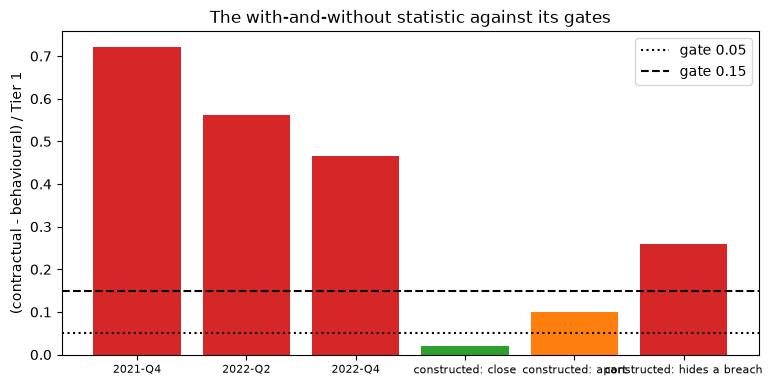

In [8]:
# Run the with-and-without test at the three dates and on three constructed pairs of measures
battery["irrbb.eve_with_without_behavioural"] = []
cases = {}
for q, d in docs.items():
    blocks = {b["nmd_assumption"]: b for b in d["outputs"]["scenarios"] if b["calibration"] == "2024"}
    beh, con = blocks["behavioural"]["eve_risk_measure"], blocks["contractual"]["eve_risk_measure"]
    cases[q] = rv_irrbb.eve_with_without_behavioural(beh, con, blocks["behavioural"]["outlier"]["tier1"])
    battery["irrbb.eve_with_without_behavioural"].append(cases[q].light.value)
pairs = {"constructed: close": (0.20, 0.22), "constructed: apart": (0.20, 0.30)}
pairs["constructed: hides a breach"] = (0.14, 0.40)
for label, (beh, con) in pairs.items():
    cases[label] = rv_irrbb.eve_with_without_behavioural(beh * 1000.0, con * 1000.0, 1000.0)
for label, run in cases.items():
    print(f"{label:28s} statistic {run.statistic:.4f} | {LIGHT[run.light.value]}")
    flag = ("no", "yes")[run.extras["hidden_breach"]]
    print(f"    hidden breach: {flag}")
colours = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(list(cases), [run.statistic for run in cases.values()], color=[colours[r.light.value] for r in cases.values()])
ax.axhline(0.05, color="black", linestyle=":", label="gate 0.05")
ax.axhline(0.15, color="black", linestyle="--", label="gate 0.15")
ax.set_ylabel("(contractual - behavioural) / Tier 1")
ax.set_title("The with-and-without statistic against its gates")
ax.tick_params(axis="x", labelsize=8)
ax.legend()
plt.show()

The first three bars are the bank at its three dates: the difference between the contractual and the behavioural measure is 0.7222, 0.5623 and 0.4655 of Tier 1, far above the red gate of 0.15, so the lights are red, and the hidden-breach flag is no because both measures breach the 15 percent line. The three constructed bars show the other lights: a difference of 0.02 is green, 0.10 is amber, and the pair 0.14 and 0.40 is red at 0.26 with the flag yes, because the behavioural measure passes the line and the contractual one does not. The picture shows how the rule reads. It cannot say which of the two readings is the truth, only that the bank reported them far apart, and that the gap narrows over the three dates.

### Step 5: the change at a limit breach

The Federal Reserve's review of Silicon Valley Bank found that the bank "made counterintuitive modeling assumptions about the duration of deposits to address the limit breach rather than managing the actual risk" (Board of Governors of the Federal Reserve System, 2023, https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). `irrbb.behavioural_change_at_breach` turns that into a test: given a series of values of a behavioural parameter on increasing dates and a flag per date that says whether a limit was breached in the window ending there, it counts the dates where the value changed ($v_t \ne v_{t-1}$) and the flag is true. The statistic is that count; the light is red when it is at least one, green when it is zero, `not_evaluated` with fewer than two dates. In C14 the parameter is the weighted average maturity of the fitted replicating portfolio of the wholesale deposits, and the flag is the standardised outlier test of the date. The next cell builds the history up to each date from the committed values and runs the engine, then runs it on two controls, a parameter that never changes and a parameter that changes while no limit is breached. Notebook 08 examines what the test does and does not discriminate.

dates of the history: ['2021-12-31', '2022-06-30', '2022-12-31']
average maturity (y): [4.7595 4.2049 5.    ] | breach flag: [ True  True  True]
2021-12-31: n = 1 | not evaluated
    flagged changes: []
2022-06-30: n = 2 | red
    flagged changes: ['2022-06-30']
2022-12-31: n = 3 | red
    flagged changes: ['2022-06-30', '2022-12-31']
constant parameter: green | flagged changes: []
changes without a breach: green | flagged changes: []


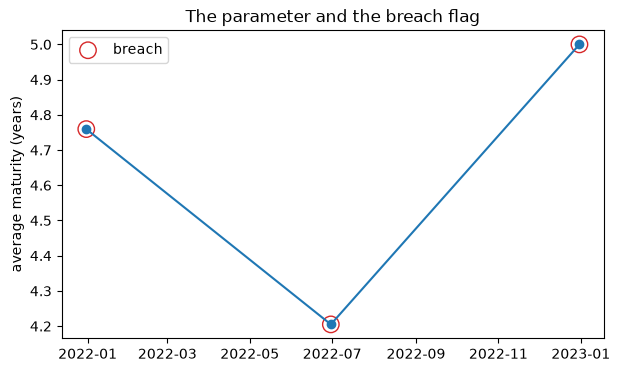

In [9]:
# Build the history of the average maturity and of the breach flag up to each date and run the test
dates = [d["outputs"]["valuation_date"] for d in docs.values()]
by_date = {m["valuation_date"]: m["weighted_average_maturity_years"] for m in fit["nmd_models"]}
values = np.array([by_date[day] for day in dates])
breach = np.array([bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()])
stamp = np.array(dates, dtype="datetime64[D]")
print("dates of the history:", dates)
print("average maturity (y):", np.round(values, 4), "| breach flag:", breach)
battery["irrbb.behavioural_change_at_breach"] = []
for k in (1, 2, 3):
    run = rv_irrbb.behavioural_change_at_breach(values[:k], stamp[:k], breach[:k])
    battery["irrbb.behavioural_change_at_breach"].append(run.light.value)
    print(f"{dates[k - 1]}: n = {run.n} | {LIGHT[run.light.value]}")
    print(f"    flagged changes: {run.extras.get('flagged_dates', [])}")
ctrl = {"constant parameter": (np.full(3, values[0]), breach)}
ctrl["changes without a breach"] = (values, np.zeros(3, dtype=bool))
for label, (series, flag) in ctrl.items():
    control = rv_irrbb.behavioural_change_at_breach(series, stamp, flag)
    print(f"{label}: {LIGHT[control.light.value]} | flagged changes: {control.extras.get('flagged_dates', [])}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(stamp, values, marker="o", color="tab:blue")
ax.scatter(stamp[breach], values[breach], s=140, facecolors="none", edgecolors="tab:red", label="breach")
ax.set_ylabel("average maturity (years)")
ax.set_title("The parameter and the breach flag")
ax.legend()
plt.show()

The line is the weighted average maturity of the fitted wholesale deposits at the three dates, 4.76, 4.20 and 5.00 years, and the red circles mark the dates where the standardised outlier test is breached: all three. The test needs two dates to compare, so the first date is not evaluated; at the second the parameter changed and a limit was breached, one flagged change, red; at the third it changed again, two flagged changes, red. The controls behave as the rule says: a parameter that never changes, or one that changes while no limit is breached, is green. Two cautions apply. Every date is in breach, and the parameter is fitted again at each date, so it moves by construction; the red says the pattern is present, not that anyone chose the number to relieve a breach. Notebook 08 takes this apart.

### Step 6: the out-of-sample projection

`irrbb.nii_out_of_sample` was run in notebook 04 on the 2021-Q4 projection (a relative error of 16.2 percent, amber). The other two dates have no realised year. The next cell runs it on the 2021-Q4 projection, on a projection within 5 percent of the realised change, on one twice as large and on a missing realised change, and then draws the whole battery of the case, one light per test and date.

projection of 2021-Q4        amber | relative error 0.1617
5% from the realised         green | relative error 0.0500
twice the realised           red | relative error 1.0000
no realised change           not evaluated | relative error nan


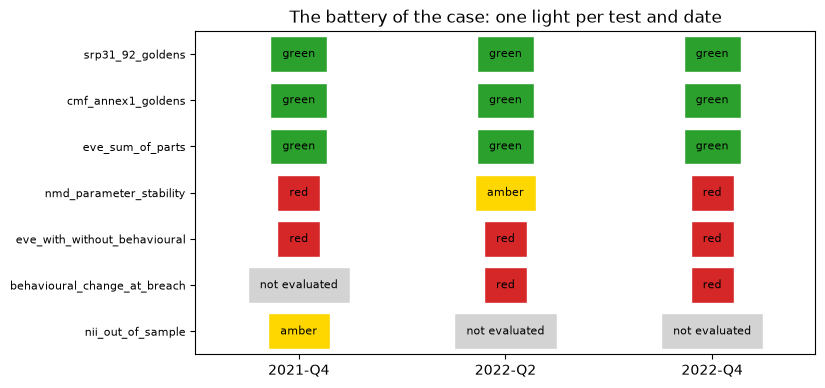

In [10]:
# The out-of-sample test on the projection of 2021-Q4 and on three controls, then the battery of the case
oos = docs["2021-Q4"]["outputs"]["out_of_sample"]
projected, realised = oos["projected_delta_nii"], oos["realised_delta_nii"]
controls = {"projection of 2021-Q4": (projected, realised), "5% from the realised": (realised * 1.05, realised)}
controls.update({"twice the realised": (realised * 2.0, realised), "no realised change": (projected, None)})
for label, (proj, real) in controls.items():
    run = rv_irrbb.nii_out_of_sample(proj, real)
    print(f"{label:28s} {LIGHT[run.light.value]} | relative error {run.statistic:.4f}")
battery["irrbb.nii_out_of_sample"] = []
for d in docs.values():
    o = d["outputs"]["out_of_sample"]
    run = rv_irrbb.nii_out_of_sample(o["projected_delta_nii"] or 0.0, o["realised_delta_nii"])
    battery["irrbb.nii_out_of_sample"].append(run.light.value)
tint = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgrey"}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(len(battery) - 0.5, -0.5)
ax.set_xticks(range(3), list(docs))
ax.set_yticks(range(len(battery)), [k.replace("irrbb.", "") for k in battery], fontsize=8)
for i, row in enumerate(battery.values()):
    for j, light in enumerate(row):
        box = {"facecolor": tint[light], "edgecolor": "white", "boxstyle": "square,pad=1.1"}
        ax.text(j, i, LIGHT[light], ha="center", va="center", fontsize=8, bbox=box)
ax.set_title("The battery of the case: one light per test and date")
plt.show()

The printed controls come first: the projection of 2021-Q4 is amber with a relative error of 0.1617, one within 5 percent of the realised change is green, one twice as large is red with an error of 1.0, and a missing realised change returns no number. The grid is the case on one page. The two golden tests and the sum of parts are green at every date; the with-and-without test is red at the three dates, the stability test is red at 2021-Q4 and 2022-Q4 and amber at 2022-Q2, the change at a breach is red where it can be evaluated, and the out-of-sample test is amber at 2021-Q4 and not evaluated at the other two. The pattern is that the tests of arithmetic are green and the tests of the behavioural assumptions are not. The gates are internal to Contraste, so a red is a finding to read, not a failed compliance.

## Results

**Answer:** the tests of arithmetic pass and the tests of the behavioural assumptions do not, and every test turns red when its input is broken, so the greens mean something. The sum of parts is green at the three dates with relative residuals of 2.07e-16, 1.06e-15 and 2.48e-15, turns red when the whole is shifted by one unit (a residual of 1.42e-07 against a gate of 1e-9) and when an item is left out (2.03). The stability of the replicating weights is red at 2021-Q4 and 2022-Q4 with a statistic of 0.5243 and amber at 2022-Q2 with 0.1967, and the with-and-without test is red at the three dates with statistics of 0.7222, 0.5623 and 0.4655.

- **The goldens.** Both golden tests are green: the worked example of the standard has a statistic of 0.0393 (the flattener, at the printed precision) and the Chilean Annex 1 passes 19 of 19 cases with none failed. With the tolerance tightened to 0.01 bp the first turns red. They say that the implementation reproduces what the sources print; they do not say that the sources are applied correctly to a balance sheet.
- **The sum of parts.** The residual is of the order of 10^-15 at the three dates and on the Chilean peso leg of C15 (2.35e-16 over 12 items), six orders of magnitude under the gate of 10^-9. The controls show the test is alive, and also that the gate decides what it can see: the same shift of one unit is green under a gate of 10^-6. The test cannot see an error that is present in both the items and the whole.
- **The stability of the weights.** The average maturity of the wholesale deposits depends on the window it is estimated on: 3.995, 2.204 and 4.759 years at 2021-Q4, a swing of 2.5559 years between consecutive windows, and 2.204, 4.759 and 5.000 at 2022-Q4. The value the bank would report is the one of the last window, so the window is a lever. This is the weakest result of the case.
- **The two readings of the EVE.** The with-and-without test is red at the three dates with no hidden breach: the behavioural measure and the contractual one are on the same side of the 15 percent line, but far apart. The constructed pairs give green at 0.0200, amber at 0.1000 and a red with a hidden breach at 0.2600.
- **The change at a breach.** The weighted average maturity is 4.7595, 4.2049 and 5.0 years at the three dates and the outlier test is breached at all three. The test is not evaluated at the first date, red at the second (one flagged change, at 2022-06-30) and red at the third (two). Every date is in breach and the parameter is re-estimated at each date, so it moves by construction; the red says that the pattern is present, not that anyone chose the number. A constant parameter, or a change without a breach, is green. Notebook 08 takes this apart.
- **The out-of-sample test.** Amber at 2021-Q4 (a relative error of 0.1617), green for a projection within 5 percent, red for one twice the realised change, and not evaluated at the other two dates, where the bank filed no later report.
- **What the tests state.** The gates are Contraste internal gates, not regulatory thresholds: a red is a finding to read, not a failed compliance. They do not show whether a green balance sheet is right; they show that it is internally consistent.

## Summary

- The engine holds seven IRRBB validation tests; each one is a function that returns a `TestResult`, states its light rule, and records its thresholds as Contraste internal gates, never as regulation.
- A test is shown not to be vacuous by changing one input: a one-unit shift of the whole turns the sum of parts red, a looser gate turns it green, and a missing item turns it red.
- The stability of the replicating weights is the weakest result: red at two of three dates, with swings of the average maturity above two years between windows.
- The test that flags a behavioural change at a breach is red at two dates, and notebook 08 examines what that does and does not mean; the out-of-sample test is evaluated at one date only, because the bank filed no later report.

**What to try next.** Change `gap_amber` and `gap_red` in `nmd_parameter_stability` and see which dates change colour. Then continue with notebook 06, the Chilean Annex 1.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 to SRP31.92 (the worked example), SRP31.82 to SRP31.83 and SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book (the replicating portfolio and the stability of its weights). https://www.bis.org/bcbs/publ/d368.htm
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1 (the Chilean formulas and tables), as transcribed in dossier 03, F.2, and in the engine's golden test.
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research, sections D.3 and D.7.